In [1]:
!pip3 install scanpy==1.9.3

In [2]:
!pip3 install scib-metrics==0.5.1 #bug in version from requirements

In [3]:
!pip3 install leidenalg==0.10.1

In [4]:
!pip3 install louvain==0.8.1

## Imports

In [5]:
import scanpy as sc
import numpy as np
import pandas as pd
import metrics_lib as metrics
import os

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2024-04-05 03:13:18.093508: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9373] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-05 03:13:18.093560: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-05 03:13:18.095106: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1534] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Set global variables

In [6]:
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Data'))
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results'))

In [7]:
#set variables to subset data
dataset="Sheppard_2020"
condition="SCD"
mode="sample"

## load and prep Data

### load and prep embedding 

In [19]:
adata = sc.read_h5ad(f"{DATA_DIR}/Mapping/sheppard_sample.h5ad")

In [20]:
adata.obs.dataset

CGATGTAAGTTACGGG_SC10                   Misharin_Budinger_2018
ATTCTACCAAGGTTCT_HD68                    Banovich_Kropski_2020
P1_2_TGCTGCTAGCTCCTCT                             Krasnow_2020
CTGATAGTCTTAGAGC_F01367                  Banovich_Kropski_2020
D344_Brus_Dis1_CATTCGCGTGCCTGCA-1-14         Barbry_Leroy_2020
                                                 ...          
AGCAGCCAGTACGCCC_IPF3                                 IPF3_Lin
TCAGCTCTCTAGCACA_IPF3                                 IPF3_Lin
CGAATGTAGTGGTAAT_NML3                                 NML3_All
GTCATTTTCTTAGAGC_IPF3                                 IPF3_Lin
GGAATAAAGCTAAGAT_SCD2                                 SCD2_All
Name: dataset, Length: 664964, dtype: category
Categories (29, object): ['Banovich_Kropski_2020', 'Barbry_Leroy_2020', 'IPF1_Lin', 'IPF2_All', ..., 'SCD2_Lin', 'Seibold_2020_10Xv2', 'Seibold_2020_10Xv3', 'Teichmann_Meyer_2019']

In [ ]:
#set the "dataset" variable correctly

In [22]:
adata.obs.dataset = adata.obs.dataset.astype(str)
adata.obs.loc[adata.obs.study == "Sheppard2020","dataset"] ="Sheppard_2020"
adata.obs.dataset = adata.obs.dataset.astype("category")

In [23]:
# make X to obsm
adata.obsm["X_scanvi"] = adata.X

In [24]:
#subset to dataset
adata=adata[(adata.obs.dataset == dataset )|(adata.obs['core_or_extension']=="core") ].copy()

In [25]:
adata.obs.loc[~(adata.obs.dataset == dataset), "condition"]="NML"

In [26]:
#subset to condition
adata=adata[(adata.obs.condition == condition )|(adata.obs['core_or_extension']=="core") ].copy()

In [27]:
adata

AnnData object with n_obs × n_vars = 603361 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'tis


### load and prep query_counts

In [28]:
adata_query=sc.read_h5ad(f"{DATA_DIR}/Query_counts/subsetted_HLCA.h5ad")

In [29]:
del adata_query.obsm["X_scanvi_emb"] #not the one we are working with

In [30]:
adata_query

AnnData object with n_obs × n_vars = 209101 × 56295
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', '

In [31]:
#set obs

In [32]:
adata[adata.obs.core_or_extension=="extension"].obs.index

Index(['TCGTACCCATGATCCA_SCD1', 'CGTCCATTCGCCCTTA_SCD1',
       'AAGGAGCGTGGTTTCA_SCD1', 'TGCCCATGTTCAGCGC_SCD1',
       'TGAGCCGAGGAGTCTG_SCD2', 'CTGTTTAAGTTAGGTA_SCD1',
       'CGGACTGCACAGGAGT_SCD1', 'GCTGCAGGTAAGGGCT_SCD1',
       'AACGTTGCAGCGTAAG_SCD1', 'CACAGGCGTATTACCG_SCD1',
       ...
       'TGACGGCAGAGTGAGA_SCD1', 'TGACTAGCATTGGTAC_SCD1',
       'GTGCTTCAGGAGCGTT_SCD1', 'GAAATGATCTTCGGTC_SCD1',
       'TAGACCAGTGTGAAAT_SCD2', 'GCGGGTTTCGCGTTTC_SCD2',
       'GAGCAGACAGCCAATT_SCD1', 'AGCTCCTTCGCAAACT_SCD1',
       'TCGGTAAAGCGTAATA_SCD2', 'GGAATAAAGCTAAGAT_SCD2'],
      dtype='object', length=18417)

In [33]:
#new index (remove tsukui to synchronize data)
adata_query.obs.index= [i.strip("_tsukui") for i in adata_query.obs.index]

In [34]:
#subset to only query of interest (dataset and condition)
adata_query =  adata_query[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [35]:
adata_query.obs = adata.obs.loc[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [36]:
adata_query.obsm["X_scanvi"] = adata[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))].X

In [37]:
adata_query

AnnData object with n_obs × n_vars = 18417 × 56295
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 't

## run metrics

In [38]:
#set some variables for running metrics
obsm_emb_key = 'X_scanvi'
donor_key= 'donor_id'
dataset_key="dataset"
sample_key="sample"
original_emb_key=None
batch_key = "sample"

In [39]:
scib_results = metrics.calculate_scib_metrics(adata, obsm_emb_key, batch_key, dataset_key, sample_key, dry_run=False)

Time to complete scib neighbors calculation: 594.413 s
Time to complete lisi_batch: 8.146 s
Time to complete kbet_batch: 2.343 s


In [40]:
symphony_results = metrics.calculate_symphony_metrics(adata, adata_query, obsm_emb_key, donor_key, dataset_key, sample_key, dry_run=False)

Time to complete symphony metrics neighbors calculation: 3.052 s
Time to complete lisi_query_donor: 0.912 s
Time to complete wiq_knn_corr: 127.666 s


In [41]:
other_results = metrics.calculate_other_metrics(adata, adata_query, obsm_emb_key, dataset_key, sample_key, dry_run=False)

/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell


Time to complete cluster_preservation_score: 66.833 s


In [42]:
#save results
adata.obs["lisi_batch"] = scib_results["lisi_batch"]["per_cell"]
adata.obs["kbet_batch"] = scib_results["kbet_batch"]["per_cell"]
adata.obs['lisi_query_donor'] = symphony_results['lisi_query_donor']["per_cell"]
adata.obs['wiq_knn_corr'] = symphony_results['wiq_knn_corr']["per_cell"]
adata.obs['cluster_preservation_score']=other_results['cluster_preservation_score']["per_cell"]

In [43]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].dropna()

,lisi_batch,kbet_batch,lisi_query_donor,wiq_knn_corr,cluster_preservation_score
TCGTACCCATGATCCA_SCD1,9.673150e-04,0.0,0.000000e+00,-0.029753,0.0
CGTCCATTCGCCCTTA_SCD1,3.540890e-03,0.0,2.589255e-11,-0.042821,0.0
AAGGAGCGTGGTTTCA_SCD1,1.351932e-05,0.0,0.000000e+00,0.007311,0.0
TGCCCATGTTCAGCGC_SCD1,2.337285e-04,0.0,-1.294627e-11,-0.011884,0.0
TGAGCCGAGGAGTCTG_SCD2,-2.821522e-09,0.0,6.473137e-12,-0.022755,0.0
...,...,...,...,...,...
GCGGGTTTCGCGTTTC_SCD2,4.119281e-05,0.0,0.000000e+00,0.011957,0.0
GAGCAGACAGCCAATT_SCD1,7.647636e-04,0.0,0.000000e+00,-0.003797,0.0
AGCTCCTTCGCAAACT_SCD1,3.267769e-03,0.0,1.294627e-11,-0.025702,0.0
TCGGTAAAGCGTAATA_SCD2,4.012829e-03,0.0,2.589255e-11,0.107128,0.0


In [44]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].to_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv')

## Visualize 

Run Load and prep embeddings and set global variables first

In [45]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']] = pd.read_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv',index_col = "Unnamed: 0")

In [46]:
sc.pp.neighbors(adata,n_neighbors=50)

In [47]:
sc.tl.umap(adata)

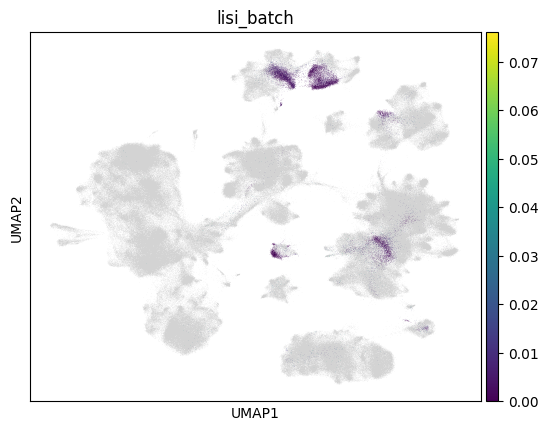

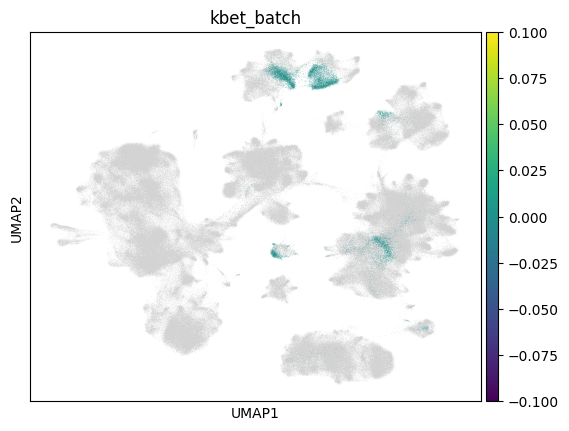

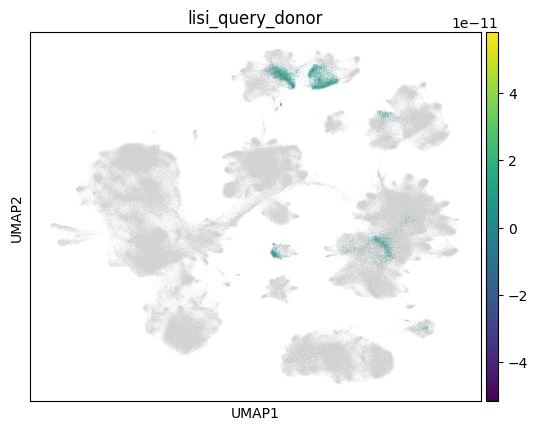

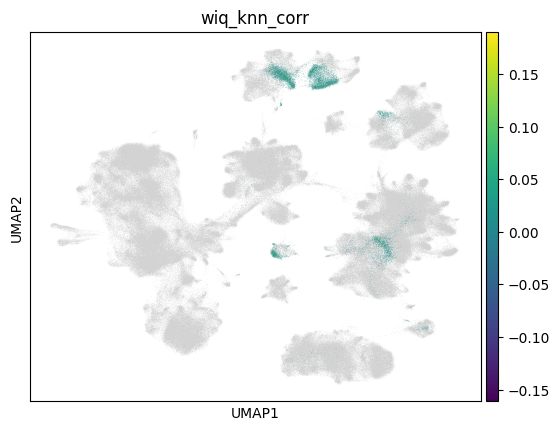

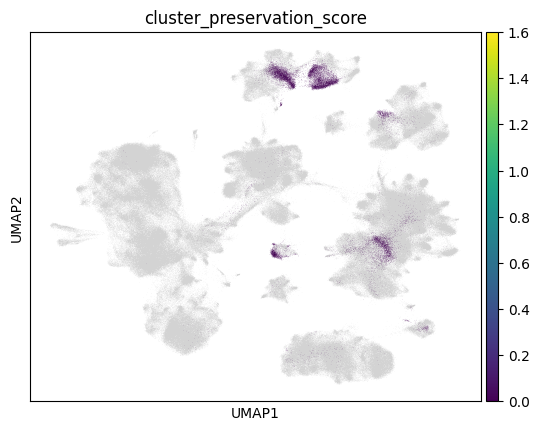

In [48]:
for metric in ["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']:
    adata.obs.loc[adata.obs.core_or_extension=="core",metric]=np.nan
    sc.pl.umap(adata,color=metric)